In [4]:
pip install rugbypy

Note: you may need to restart the kernel to use updated packages.


In [35]:
pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.


In [5]:
from rugbypy.match import *
from rugbypy.competition import *
from rugbypy.team import *
from rugbypy.venue import *
from rugbypy.player import *

In [6]:
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

In [7]:
competitions = fetch_all_competitions()
venues = fetch_all_venues()

Fetching all competition...
Fetching all venues...


In [8]:
venues.head()

,venue_id,venue_name
0,be11e8d2,Unknown
1,bc721fea,Stade du Hameau
2,5b691aae,Stade de France
3,b3faf6cf,Stadio Comunale di Monigo
4,fc3a9a61,at Franklin's Gardens


In [9]:
test_match_ids = ['96c775f2', '423a2845', 'f44ef210', '7a1361e7', '5a4d4920', 'd1999468', '05d59524', '15f804f7']


test_match_names = competitions.loc[competitions['competition_id'].isin(test_match_ids)]

test_match_names

,competition_id,competition_name
1,423a2845,The Rugby Championship
2,7a1361e7,Six Nations
10,15f804f7,British and Irish Lions Tour
11,96c775f2,International Test Match
12,5a4d4920,Rugby World Cup
20,d1999468,Pacific Nations Cup
22,f44ef210,Autumn Nations Series
24,05d59524,Rugby Europe Championship


In [10]:
six_nations_md_5 = fetch_matches_by_date(date = "20250315")

six_nations_md_5 = six_nations_md_5.loc[six_nations_md_5['competition_id'].isin(test_match_ids)]

six_nations_md_5

Fetching matches on date: 20250315...


,match_id,competition_id,home_team_id,home_team,away_team_id,away_team
4,3693cfdf,7a1361e7,67d88578,France,4409215c,Scotland
8,80928ead,7a1361e7,094dae60,Wales,f60f757d,England
12,d6fcbafa,7a1361e7,d0cffe5e,Italy,165b36e5,Ireland


In [11]:
home_teams = six_nations_md_5[['home_team_id', 'home_team']]
away_teams = six_nations_md_5[['away_team_id', 'away_team']]

home_teams = home_teams.rename(columns={'home_team_id': 'team_id', 'home_team': 'team_name'})
away_teams = away_teams.rename(columns = {'away_team_id': 'team_id', 'away_team': 'team_name'})

In [12]:
six_nations_teams = pd.concat([home_teams, away_teams], ignore_index=True)
six_nations_teams

,team_id,team_name
0,67d88578,France
1,094dae60,Wales
2,d0cffe5e,Italy
3,4409215c,Scotland
4,f60f757d,England
5,165b36e5,Ireland


In [13]:
trc_md_1 = fetch_matches_by_date(date = '20250816')

trc_md_1 = trc_md_1.loc[trc_md_1['competition_id'].isin(test_match_ids)]

Fetching matches on date: 20250816...


In [14]:
trc_md_1

,match_id,competition_id,home_team_id,home_team,away_team_id,away_team
0,16fb0c16,423a2845,9b93d911,South Africa,b904fef9,Australia
4,6a36aeb1,423a2845,11392c0c,Argentina,d75e45cc,New Zealand


In [15]:
home_trc = trc_md_1[['home_team_id', 'home_team']]
away_trc = trc_md_1[['away_team_id', 'away_team']]

home_trc = home_trc.rename(columns={'home_team_id': 'team_id', 'home_team': 'team_name'})
away_trc = away_trc.rename(columns={'away_team_id': 'team_id', 'away_team': 'team_name'})

trc_nations = pd.concat([home_trc, away_trc], ignore_index=True)

In [16]:
trc_nations

,team_id,team_name
0,9b93d911,South Africa
1,11392c0c,Argentina
2,b904fef9,Australia
3,d75e45cc,New Zealand


In [17]:
test_nations = pd.concat([six_nations_teams, trc_nations], ignore_index=True)

test_nations

,team_id,team_name
0,67d88578,France
1,094dae60,Wales
2,d0cffe5e,Italy
3,4409215c,Scotland
4,f60f757d,England
5,165b36e5,Ireland
6,9b93d911,South Africa
7,11392c0c,Argentina
8,b904fef9,Australia
9,d75e45cc,New Zealand


In [18]:
british_irish_lions = fetch_matches_by_date(date = '20250719')

british_irish_lions = british_irish_lions.loc[british_irish_lions['competition_id'].isin(test_match_ids)]

Fetching matches on date: 20250719...


In [19]:
british_irish_lions = british_irish_lions[['away_team_id', 'away_team']].rename(columns={'away_team_id': 'team_id', 'away_team': 'team_name'})

In [20]:
test_nations = pd.concat([test_nations, british_irish_lions], ignore_index=True)

In [21]:
test_nations

,team_id,team_name
0,67d88578,France
1,094dae60,Wales
2,d0cffe5e,Italy
3,4409215c,Scotland
4,f60f757d,England
5,165b36e5,Ireland
6,9b93d911,South Africa
7,11392c0c,Argentina
8,b904fef9,Australia
9,d75e45cc,New Zealand


In [22]:
## picked out a Rugby World Cup Matchday where Japan/Fiji Played

rwc_23_09_10 = fetch_matches_by_date(date="20230910")

rwc_23_09_10 = rwc_23_09_10.loc[rwc_23_09_10['competition_id'].isin(test_match_ids)]


Fetching matches on date: 20230910...


In [23]:
japan = rwc_23_09_10[rwc_23_09_10['home_team'] == "Japan"]

japan = japan[['home_team_id', 'home_team']].rename(columns={'home_team_id': 'team_id', 'home_team': 'team_name'})


In [24]:
fiji = rwc_23_09_10[rwc_23_09_10['away_team'] == "Fiji"]

fiji = fiji[['away_team_id', 'away_team']].rename(columns = {'away_team_id': 'team_id', 'away_team': 'team_name'})

In [26]:
test_nations = pd.concat([test_nations, japan, fiji], ignore_index=True)

test_nations

,team_id,team_name
0,67d88578,France
1,094dae60,Wales
2,d0cffe5e,Italy
3,4409215c,Scotland
4,f60f757d,England
5,165b36e5,Ireland
6,9b93d911,South Africa
7,11392c0c,Argentina
8,b904fef9,Australia
9,d75e45cc,New Zealand


In [27]:
all_matches = fetch_all_matches()

tier_1_test_matches = all_matches[all_matches['home_team'].isin(test_nations['team_name']) |
                                   all_matches['away_team'].isin(test_nations['team_name'])]

tier_1_test_matches.head(5)

Fetching all matches...


,match_id,home_team,away_team,date
1237,26eb0d57,Ireland,Wales,20220205
6768,d803469c,Scotland,England,20220205
2386,4a49c716,France,Italy,20220206
3966,7ec3e5e5,Wales,Scotland,20220212
3559,71ccf2fb,France,Ireland,20220212


In [28]:
tier_1_test_ids = tier_1_test_matches['match_id']
matches = pd.DataFrame()
for id in tier_1_test_ids:
    matches = pd.concat([matches, fetch_match_details(match_id=id)], 
                        ignore_index=True)


Fetching match details for match_id: 26eb0d57...
Fetching match details for match_id: d803469c...
Fetching match details for match_id: 4a49c716...
Fetching match details for match_id: 7ec3e5e5...
Fetching match details for match_id: 71ccf2fb...
Fetching match details for match_id: c960c247...
Fetching match details for match_id: eb863c39...
Fetching match details for match_id: 0f429181...
Fetching match details for match_id: 4b7ddccc...
Fetching match details for match_id: 6b6585fc...
Fetching match details for match_id: db462616...
Fetching match details for match_id: b50b968e...
Fetching match details for match_id: cc3c0a71...
Fetching match details for match_id: 8e84569c...
Fetching match details for match_id: d82fd124...
Fetching match details for match_id: 57934f49...
Fetching match details for match_id: dc868afb...
Fetching match details for match_id: 06752427...
Fetching match details for match_id: 226e92ee...
Fetching match details for match_id: e7917048...
Fetching match detai

In [29]:
matches.head(5)

,match_id,date,kickoff_time,season,competition_id,competition,venue_id,venue,city_played,home_team,...,away_team_id,home_score,away_score,completed,is_tournament,played_on_grass,attendance,home_team_form,away_team_form,referee
0,26eb0d57,20220205,NaN,2022,7a1361e7,Six Nations,07b0586c,Aviva Stadium,Dublin,Ireland,...,094dae60,29,7,True,1.0,1.0,None,LWWLW,LLWLW,None
1,d803469c,20220205,NaN,2022,7a1361e7,Six Nations,a35811c5,Scottish Gas Murrayfield,Edinburgh,Scotland,...,f60f757d,20,17,True,1.0,1.0,None,WLLWW,WWWWW,None
2,4a49c716,20220206,NaN,2022,7a1361e7,Six Nations,5b691aae,Stade de France,Saint-Denis,France,...,d0cffe5e,37,10,True,1.0,1.0,None,WWLLL,WLWLL,None
3,7ec3e5e5,20220212,NaN,2022,7a1361e7,Six Nations,fe933f9f,Principality Stadium,Cardiff,Wales,...,4409215c,20,17,True,1.0,1.0,None,LLWLW,WLLWW,None
4,71ccf2fb,20220212,NaN,2022,7a1361e7,Six Nations,5b691aae,Stade de France,Saint-Denis,France,...,165b36e5,30,24,True,1.0,1.0,None,WWLLL,LWWLW,None


In [30]:
matches.columns

Index(['match_id', 'date', 'kickoff_time', 'season', 'competition_id', 'competition', 'venue_id', 'venue', 'city_played', 'home_team', 'away_team', 'home_team_id',
       'away_team_id', 'home_score', 'away_score', 'completed', 'is_tournament', 'played_on_grass', 'attendance', 'home_team_form', 'away_team_form', 'referee'],
      dtype='object')

In [31]:
team_stats = pd.DataFrame()
test_team_ids = test_nations['team_id']

for id in test_team_ids:
    team_stats = pd.concat([team_stats, fetch_team_stats(team_id=id)], 
                           ignore_index=True)

team_stats.head(5)


Fetching all team stats for team_id: 67d88578...
Fetching all team stats for team_id: 094dae60...
Fetching all team stats for team_id: d0cffe5e...
Fetching all team stats for team_id: 4409215c...
Fetching all team stats for team_id: f60f757d...
Fetching all team stats for team_id: 165b36e5...
Fetching all team stats for team_id: 9b93d911...
Fetching all team stats for team_id: 11392c0c...
Fetching all team stats for team_id: b904fef9...
Fetching all team stats for team_id: d75e45cc...
Fetching all team stats for team_id: a924d2bc...
No team stats for {team_id} because the team id does not exist. Please raise an issue!
Fetching all team stats for team_id: f97333f3...
Fetching all team stats for team_id: 3a1983b3...
Fetching all team stats for team_id: f97333f3...
Fetching all team stats for team_id: 3a1983b3...


,team_id,team,game_date,team_vs,team_vs_id,match_id,players,score,team_vs_score,22m_entries,...,offload,pc_possession_first,pc_possession_second,pc_territory_first,pc_territory_second,rucks_total,runs,scrums_total,total_free_kicks_conceded,turnover_knock_on
0,67d88578,France,20220206,Italy,d0cffe5e,4a49c716,"[0042c61a, 01b8ac07, 0e930fa8, 1d490b9e, 252ec...",NaN,NaN,NaN,...,9.0,0.62,0.54,0.66,0.64,96.0,124.0,5.0,0.0,7.0
1,67d88578,France,20220212,Ireland,165b36e5,71ccf2fb,"[0042c61a, 01b8ac07, 065c26ea, 0e930fa8, 1d490...",NaN,NaN,NaN,...,8.0,0.52,0.43,0.55,0.48,83.0,101.0,5.0,1.0,7.0
2,67d88578,France,20220226,Scotland,4409215c,eb863c39,"[0042c61a, 01b8ac07, 065c26ea, 0e930fa8, 252ec...",NaN,NaN,NaN,...,10.0,0.45,0.39,0.39,0.61,41.0,75.0,9.0,1.0,6.0
3,67d88578,France,20220311,Wales,094dae60,6b6585fc,"[065c26ea, 0e930fa8, 1d490b9e, 252ecbf2, 26273...",NaN,NaN,NaN,...,10.0,0.53,0.41,0.55,0.33,69.0,98.0,6.0,1.0,9.0
4,67d88578,France,20220319,England,f60f757d,cc3c0a71,"[0042c61a, 065c26ea, 0e930fa8, 1d490b9e, 252ec...",NaN,NaN,NaN,...,13.0,0.51,0.39,0.60,0.27,71.0,98.0,9.0,0.0,8.0


In [32]:
team_stats.columns

Index(['team_id', 'team', 'game_date', 'team_vs', 'team_vs_id', 'match_id', 'players', 'score', 'team_vs_score', '22m_entries', '22m_conversion', 'line_breaks', 'carries',
       'kicks', 'post_contact_metres', 'dominant_tackles', 'tackles_made', 'tackles_missed', 'turnovers_won', 'tackle_turnover', 'tackle_offload_allowed',
       'ruck_speed_0_3_pct', 'ruck_speed_3_6_pct', 'ruck_speed_6_plus_pct', 'rucks_won', 'possession', 'territory', 'tries', 'conversions', 'penalty_goals', 'drop_goals',
       'clean_breaks', 'defenders_beaten', 'kicks_from_hand', 'lineout_success', 'lineouts_won', 'mauls_won', 'metres_carried', 'offloads', 'passes', 'penalties_conceded',
       'red_cards', 'scrums_won', 'tackles', 'total_lineouts', 'total_scrums', 'turnovers_conceded', 'yellow_cards', 'penalty_tries', 'try_assists', 'turnovers',
       'conversion_goals', 'kick_percent_success', 'lineout_won_steal', 'mauls_total', 'meters_run', 'missed_tackles', 'offload', 'pc_possession_first',
       'pc_poss

In [33]:
team_stats = team_stats[['team_id', 'team', 'game_date', 'team_vs', 'team_vs_id',
                         'match_id', '22m_entries', '22m_conversion',
                         'line_breaks', 'carries', 'kicks', 'post_contact_metres', 'dominant_tackles',
                         'tackles_made', 'tackles_missed', 'turnovers_won', 'tackle_turnover', 'tackle_offload_allowed',
                         'ruck_speed_0_3_pct', 'ruck_speed_3_6_pct', 'ruck_speed_6_plus_pct', 'rucks_won',
                         'possession', 'territory', 'tries', 'conversions', 'penalty_goals', 
                         'drop_goals', 'clean_breaks', 'defenders_beaten', 'kicks_from_hand', 'lineout_success',
                         'lineouts_won', 'mauls_won', 'metres_carried', 'offloads', 'passes', 'penalties_conceded',
                         'red_cards', 'scrums_won', 'tackles', 'total_lineouts', 'total_scrums', 'turnovers_conceded',
                         'yellow_cards', 'penalty_tries', 'turnovers', 'kick_percent_success', 'lineout_won_steal',
                         'mauls_total', 'meters_run', 'missed_tackles', 'offload', 'pc_possession_first',
                         'pc_possession_second', 'pc_territory_first', 'pc_territory_second', 'rucks_total',
                         'runs', 'scrums_total', 'total_free_kicks_conceded', 'turnover_knock_on']]

In [36]:
## Excel sheets made for Observation

team_stats.to_excel('team_stats.xlsx', index = False)
tier_1_test_matches.to_excel('test_matches.xlsx', index = False)
matches.to_excel('detailed_test_matches.xlsx', index = False)



In [37]:
## Joining Data Sets

drop_cols = ['team', 'team_vs', 'team_vs_id', 'game_date', 'score', 'team_vs_score']

team_stats = team_stats.drop(columns=[c for c in drop_cols if c in team_stats.columns])


In [38]:
stat_cols = [c for c in team_stats.columns if c not in ('team_id', 'match_id')]

In [39]:
home_team_stats = team_stats.rename(columns={
    'team_id': 'home_team_id',
    **{c: f'home_{c}' for c in stat_cols}
})

away_team_stats = team_stats.rename(columns={
    'team_id': 'away_team_id',
    **{c: f'away_{c}' for c in stat_cols}
})


match_details = pd.merge(matches, home_team_stats, on = ['match_id', 'home_team_id'], how = 'left')

match_details = match_details.merge(away_team_stats, on = ['match_id','away_team_id'], how = 'left')

In [40]:
match_details.head(5)

,match_id,date,kickoff_time,season,competition_id,competition,venue_id,venue,city_played,home_team,...,away_offload,away_pc_possession_first,away_pc_possession_second,away_pc_territory_first,away_pc_territory_second,away_rucks_total,away_runs,away_scrums_total,away_total_free_kicks_conceded,away_turnover_knock_on
0,26eb0d57,20220205,NaN,2022,7a1361e7,Six Nations,07b0586c,Aviva Stadium,Dublin,Ireland,...,8.0,0.36,0.44,0.51,0.35,80.0,95.0,6.0,0.0,9.0
1,d803469c,20220205,NaN,2022,7a1361e7,Six Nations,a35811c5,Scottish Gas Murrayfield,Edinburgh,Scotland,...,7.0,0.62,0.45,0.72,0.52,77.0,99.0,8.0,2.0,5.0
2,4a49c716,20220206,NaN,2022,7a1361e7,Six Nations,5b691aae,Stade de France,Saint-Denis,France,...,1.0,0.38,0.46,0.34,0.36,73.0,80.0,6.0,0.0,11.0
3,7ec3e5e5,20220212,NaN,2022,7a1361e7,Six Nations,fe933f9f,Principality Stadium,Cardiff,Wales,...,7.0,0.52,0.48,0.52,0.40,114.0,131.0,7.0,0.0,5.0
4,71ccf2fb,20220212,NaN,2022,7a1361e7,Six Nations,5b691aae,Stade de France,Saint-Denis,France,...,7.0,0.48,0.57,0.45,0.52,87.0,112.0,3.0,0.0,10.0


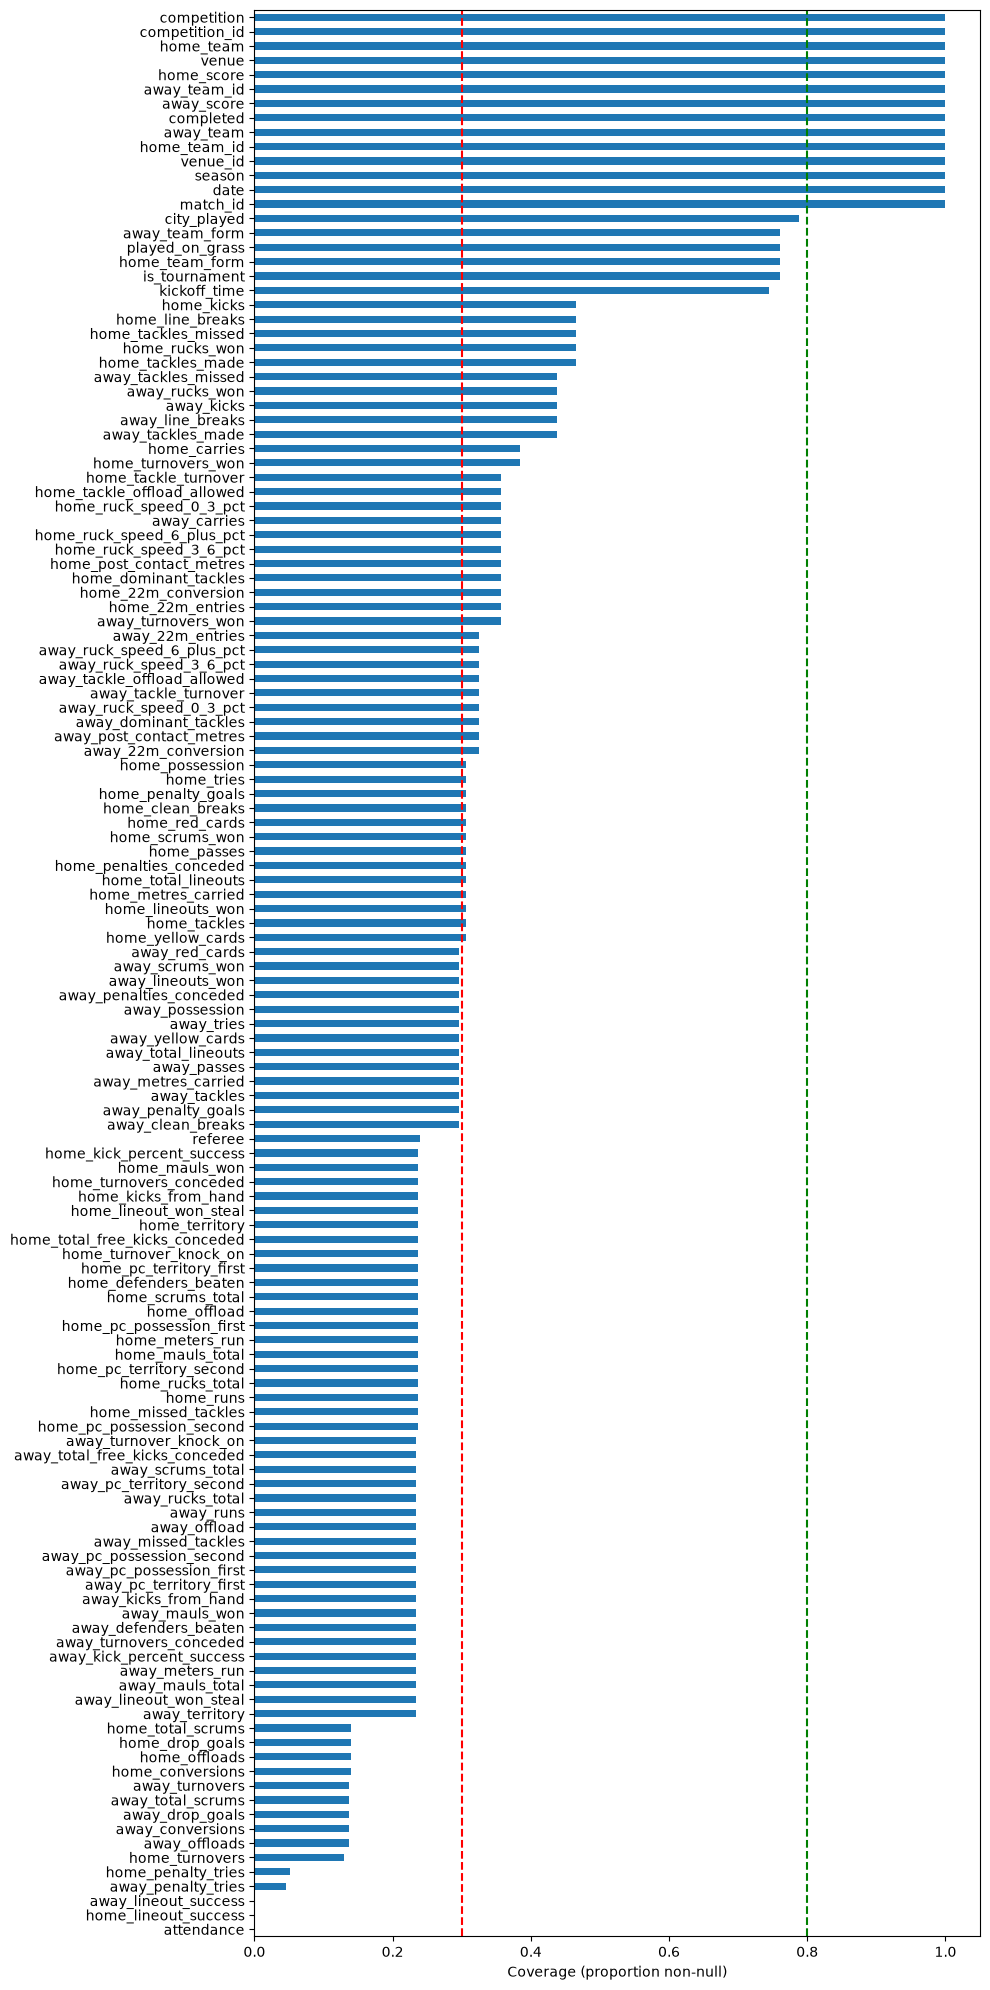

In [44]:
coverage = match_details.notna().mean().sort_values()
coverage.plot(kind='barh', figsize=(10, 20))
plt.axvline(0.30, color='red', linestyle='--', label='30% threshold')
plt.axvline(0.80, color = 'green', linestyle = '--', label = '80% threshold')
plt.xlabel('Coverage (proportion non-null)')
plt.tight_layout()

Columns to Keep for Probability Model:
- Line breaks
- Tackles missed
- Rucks won
- Tackles Made
- Kicks
- Carries
- 22 meter entries
- Turnovers won
- 22 meter conversion
- Post contact meters
- Red/Yellow cards
- Lineouts
- Possession %
- Meters carried
- Scrums won
- Penalties conceded
- Penalty goals
- Turnovers conceded

Potential Features Derived from Metrics
- Winner - Comparing scores/points
- Lineout success rate - lineouts won/number of lineouts
- Tackle success rate
- 

In [ ]:
## Wrangle match_details here

match_details.to_excel('fully_merged.xlsx', index=False)
